# Практическая работа 13. Обнаружение аномалий. Isolation Forest

### 1. Генерация и визуализация данных

Сгенерируем 100 нормальных точек и 20 выбросов, затем объединим их в один массив. Истинные метки используем только для визуализации и сравнения результатов.

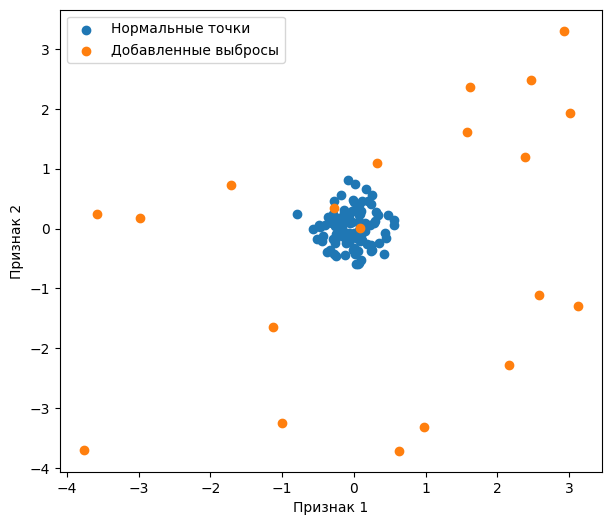

In [1]:
import numpy as np
import pandas as pd
%matplotlib inline
import matplotlib.pyplot as plt
from sklearn.ensemble import IsolationForest
from sklearn.datasets import load_diabetes

np.random.seed(42)
X = 0.3 * np.random.randn(100, 2)
X_outliers = np.random.uniform(low=-4, high=4, size=(20, 2))
X = np.vstack([X, X_outliers])
y = np.hstack([np.zeros(100), np.ones(20)])

plt.figure(figsize=(7, 6))
plt.scatter(X[y == 0, 0], X[y == 0, 1], label='Нормальные точки')
plt.scatter(X[y == 1, 0], X[y == 1, 1], label='Добавленные выбросы')
plt.xlabel('Признак 1')
plt.ylabel('Признак 2')
plt.legend()
plt.show()

### 2. Обучение Isolation Forest

Isolation Forest (изолирующий лес) — метод обнаружения аномалий без учителя. Алгоритм строит деревья изоляции, случайно выбирая признак и значение для разбиения. Аномальные объекты обычно изолируются за меньшее число разбиений, чем нормальные.

Аномальности рассчитывается по формуле:

$$s(x,n)=2^{-\frac{E[h(x)]}{c(n)}}$$

$$c(n)=2H(n-1)-\frac{2(n-1)}{n}$$

где $E[h(x)]$ — средняя длина пути по деревьям, $c(n)$ — средняя длина пути для набора из $n$ объектов, $H(k)$ — гармоническое число. Чем ближе $s(x,n)$ к 1, тем более аномальным считается объект.

Параметр contamination задаёт ожидаемую долю выбросов. Установим её равной 0,15. Используем 100 деревьев и методы fit и predict. Предсказание 1 означает нормальную точку, -1 — аномалию.

In [2]:
model = IsolationForest(n_estimators=100, max_samples='auto',
                        contamination=0.15, random_state=42)
model.fit(X)
predictions = model.predict(X)
print('Предсказания:', predictions)
print('Нормальных точек:', np.sum(predictions == 1))
print('Аномальных точек:', np.sum(predictions == -1))

Предсказания: [ 1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1  1
  1  1  1  1 -1 -1 -1 -1 -1  1 -1 -1 -1 -1 -1  1 -1 -1 -1 -1 -1 -1 -1 -1]
Нормальных точек: 102
Аномальных точек: 18


### 3. Визуализация результата работы алгоритма

Выделим найденные аномалии другим цветом и сравним результат с исходными метками.

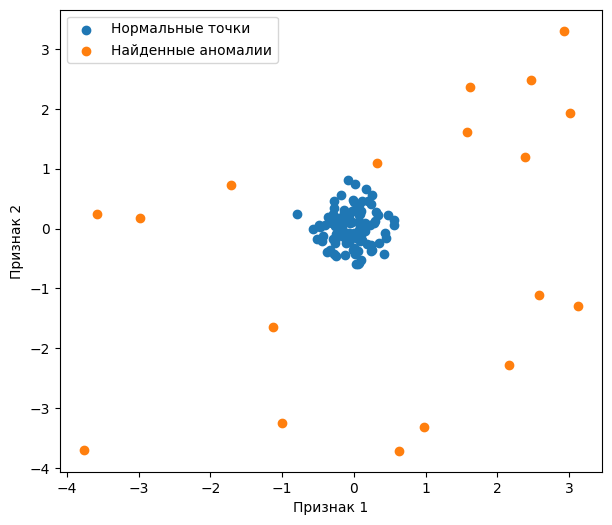

Найдено добавленных выбросов: 18
Ошибочно выделено нормальных точек: 0


In [3]:
plt.figure(figsize=(7, 6))
plt.scatter(X[predictions == 1, 0], X[predictions == 1, 1], label='Нормальные точки')
plt.scatter(X[predictions == -1, 0], X[predictions == -1, 1], label='Найденные аномалии')
plt.xlabel('Признак 1')
plt.ylabel('Признак 2')
plt.legend()
plt.show()

print('Найдено добавленных выбросов:', np.sum((y == 1) & (predictions == -1)))
print('Ошибочно выделено нормальных точек:', np.sum((y == 0) & (predictions == -1)))

### 4. График функции решения

Для визуализации оценок используется метод decision_function. В sklearn его результат отличается от теоретической оценки $s(x,n)$: чем меньше значение функции решения, тем более аномальной считается точка.


Отрицательные значения соответствуют аномалиям, неотрицательные — нормальным объектам. Построим график с цветовой шкалой, и покажем значения функции для всех наблюдений.

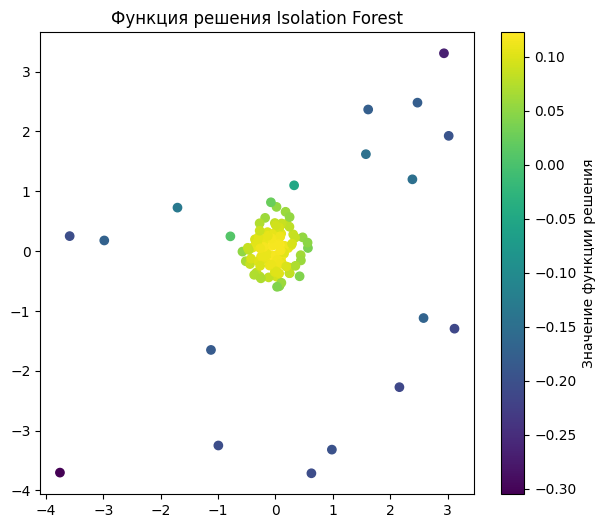

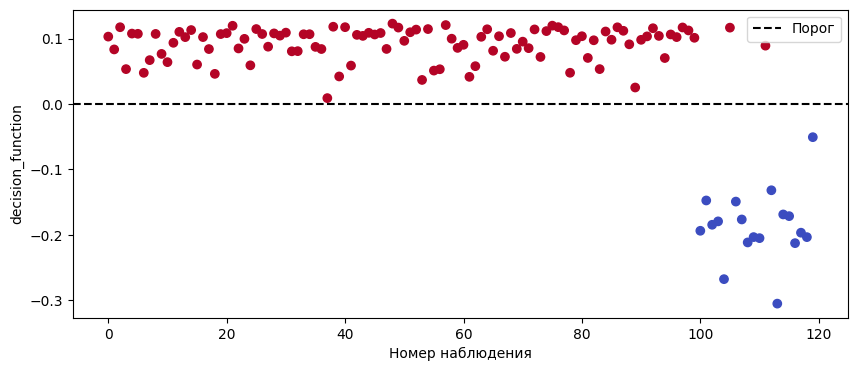

In [4]:
anomaly_scores = model.decision_function(X)
plt.figure(figsize=(7, 6))
plt.scatter(X[:, 0], X[:, 1], c=anomaly_scores, cmap='viridis')
plt.colorbar(label='Значение функции решения')
plt.title('Функция решения Isolation Forest')
plt.show()

plt.figure(figsize=(10, 4))
plt.scatter(np.arange(len(X)), anomaly_scores, c=predictions, cmap='coolwarm')
plt.axhline(0, color='black', linestyle='--', label='Порог')
plt.xlabel('Номер наблюдения')
plt.ylabel('decision_function')
plt.legend()
plt.show()

Точки, расположенные далеко от основной группы, обычно имеют меньшие значения функции решения. Ниже нулевого порога находятся 18 точек, которые модель определила как аномалии.

### 5. Эксперименты с параметрами contamination и n_estimators

Параметр contamination влияет на порог выделения аномалий, а n_estimators задаёт количество деревьев. Возьмём 50, 100 и 200 деревьев. Проверим несколько долей выбросов. Для сравнения используем число правильно найденных добавленных выбросов и число ложных срабатываний.

In [5]:
results = []
for contamination in [0.05, 0.15, 0.2]:
    for n_estimators in [50, 100, 200]:
        experiment = IsolationForest(n_estimators=n_estimators,
                                     contamination=contamination, random_state=42)
        experiment.fit(X)
        pred = experiment.predict(X)
        results.append([contamination, n_estimators,
                        np.sum(pred == -1),
                        np.sum((y == 1) & (pred == -1)),
                        np.sum((y == 0) & (pred == -1))])

results = pd.DataFrame(results, columns=['contamination', 'n_estimators',
    'Найдено аномалий', 'Верно найдено выбросов', 'Ложные срабатывания'])
print(results.to_string(index=False))

 contamination  n_estimators  Найдено аномалий  Верно найдено выбросов  Ложные срабатывания
          0.05            50                 6                       6                    0
          0.05           100                 6                       6                    0
          0.05           200                 6                       6                    0
          0.15            50                18                      18                    0
          0.15           100                18                      18                    0
          0.15           200                18                      18                    0
          0.20            50                24                      18                    6
          0.20           100                24                      18                    6
          0.20           200                24                      18                    6


При contamination=0.05 найдено 6 выбросов, при 0.15 — 18 без ложных срабатываний, а при 0.2 — 18 выбросов и 6 нормальных точек. Изменение количества деревьев в данном эксперименте не повлияло на эти показатели. Наилучший результат среди проверенных вариантов получен при contamination=0.15.